# Qwen3.8 × ARC-AGI-2: 200-task exploratory run

On November 8, 2026, Qwen3.8-27B-FP8 completed **200/200** public training-set tasks in the Colab quick exploratory workflow. Local scoring found **17/200 (8.5%) on the first candidate** and **25/200 (12.5%) with either of two recorded candidates**. This is not an official ARC-AGI-2 evaluation or evidence of RSI improvement.

This report embeds a fixed aggregate snapshot. It needs no GPU, model, network, predictions, or solutions to run; rerunning it does not fetch or score a new experiment.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
summary = pd.DataFrame([
    {'Metric': 'First candidate correct', 'Tasks': 17, 'Denominator': 200},
    {'Metric': 'Either of two correct', 'Tasks': 25, 'Denominator': 200},
    {'Metric': 'First candidate valid format', 'Tasks': 173, 'Denominator': 200},
    {'Metric': 'Either candidate valid format', 'Tasks': 195, 'Denominator': 200},
])
summary['Percent'] = summary['Tasks'] / summary['Denominator'] * 100
display(summary)

,Metric,Tasks,Denominator,Percent
0,First candidate correct,17,200,8.5
1,Either of two correct,25,200,12.5
2,First candidate valid format,173,200,86.5
3,Either candidate valid format,195,200,97.5


## Correctness and format are different

A task passes only if one candidate matches **every** test output for that task. Invalid responses count as incorrect. The second metric counts two recorded attempts, not independent samples; 18/200 task pairs had identical raw responses.

The run allowed structural recovery (removing code fences or wrapping a single grid). These transformations affect validity and scoring; the previous Qwen3-14B/32B comparison used a different protocol, so these values are not a controlled model-only comparison.

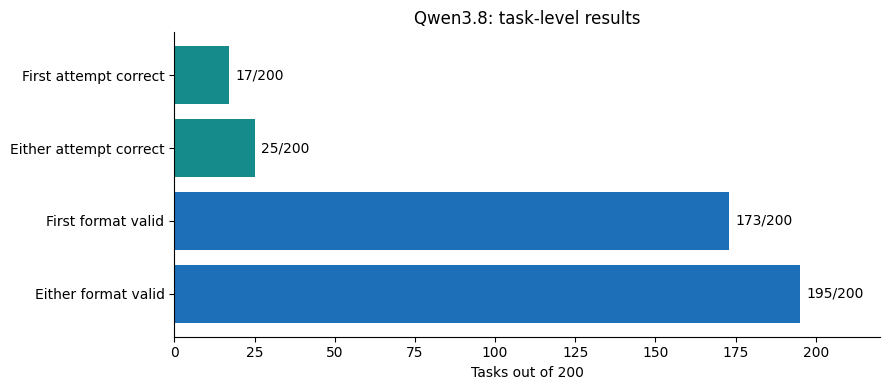

In [2]:
fig, ax = plt.subplots()
labels = ['First attempt correct', 'Either attempt correct', 'First format valid', 'Either format valid']
values = [17, 25, 173, 195]
bars = ax.barh(labels[::-1], values[::-1], color=['#168b8b', '#168b8b', '#1d70b8', '#1d70b8'][::-1])
ax.set_xlim(0, 220); ax.set_xlabel('Tasks out of 200'); ax.set_title('Qwen3.8: task-level results')
for bar, value in zip(bars, values[::-1]): ax.text(value + 2, bar.get_y() + bar.get_height()/2, f'{value}/200', va='center')
fig.tight_layout(); plt.show()

## Candidate formats and runtime

There were 400 recorded candidates. The categories below describe how each response was parsed; recovered outputs were retained as candidates. Total task inference time is the sum of recorded task durations, not end-to-end elapsed time or a cost estimate. It excludes setup, model download and loading, interruptions, and idle time.

In [3]:
formats = pd.DataFrame({'Parse mode': ['Strict', 'Wrapped single grid', 'Removed code fence', 'Invalid'], 'Candidates': [64, 269, 23, 44]})
display(formats)
print('Valid candidates: 356/400; invalid: 44/400')
print('Sum of task runtimes: 24,484.188 seconds (6.80 hours)')
print('Median task runtime: 78.724 seconds; range: 1.776–992.361 seconds')

,Parse mode,Candidates
0,Strict,64
1,Wrapped single grid,269
2,Removed code fence,23
3,Invalid,44


Valid candidates: 356/400; invalid: 44/400
Sum of task runtimes: 24,484.188 seconds (6.80 hours)
Median task runtime: 78.724 seconds; range: 1.776–992.361 seconds


## Evidence and limitations

- Hardware observed in every record: NVIDIA A100-SXM4-40GB; model `Qwen/Qwen3.8-27B-FP8`, revision `c3a462cc3d38cf351f3b26cbd763469eeb74ef81`; vLLM 0.33.0; context 18,432; output limit 4,096; temperature 0.6.
- [Experiment notebook](../experiments/003_qwen38_phase_a.ipynb): quick exploratory protocol; model loaded once and reused. The pilot gate was disabled after 2/3 pilot tasks had at least one valid response. The quick protocol does not provide the original per-task process isolation.
- 200 saved task records match the aggregate, registered task IDs and manifest. Dataset and allocation hashes matched the local files. The registered repository revision identifies referenced project code; it does **not** independently bind the edited live Colab notebook, model files, or runtime environment. The Drive folder name says `fp8-hopper`, but records report A100.
- Aggregate `phase_a_results.json` SHA-256: `f07534b2a20704cda4eb19879b43d047bfb34d865e94e24028be552ace58f77e`; manifest SHA-256: `911763ed410c9bafc12e4259bd8c29a26c5d00a2e12a3d67c5cce045c0f9cc7b`. The raw aggregate and all checkpoints are retained locally under Git-ignored `artifacts/qwen38-quick-20261108/` and in Google Drive.
- The 200 tasks come from the public training set, with uncertain prior exposure. The result is exploratory, not the reserved official evaluation. Scoring was performed locally with the project scorer; answers are not included in this notebook.